# Herhalingslabo Classificatie

Hoe weet je wanneer je welk algoritme best gebruikt ? Gebruik volgende handleiding:

**KNearestNeighbours**
- Geschikt voor classificatie en regressie
- Voor kleine/middelgrote datasets
- heel simpel, kan snel worden getrained
- werkt niet goed voor datasets met heel veel features

**Support Vector Machines**
- Vooral een standaard voor binaire classificatie, of wanneer je een duidelijke marge wilt op classificatie (=het hoofddoel van het algoritme)
- Voor kleine/middelgrote datasets
- Is kostelijker om te trainen dan KNN, maar classificeert dan wel sneller
- Kernel keuze en hyperparameter tuning zijn essentieel

**Decision Trees**
- Wanneer je een 'white box', 'explainable' model wilt
- kan zowel numerieke als categorische features makkelijk aan
- kan heel goed om met missende datapunten
- het risico op overfitting is groot. Bij twijfel, gebruik een random forest

**Random forest**
- Zelfde voordelen als decision tree, minder risico op overfitting
- Geschikt voor middelgrote/grote datasets
- Geschikt voor data met (heel) veel features
- Hebben uiteraard meer trainingstijd nodig dan een enkele decision tree

**Adaboost**
- Als data niet goed is gebalanceerd (niet evenveel items van elke klasse)
- Vermijd een onderfit. Dit model is beter dan 1 enkele onderliggende decision tree

**XGBoost**
- XGBoost is bijna *altijd* een goede keuze
- Middelgrote / grote datasets
- Datasets met (heel) veel features
- De implementatie van XGBoost staat, ondanks dat het een boosting algoritme is, toch deels parallellisatie toe.

In de praktijk zijn er vaak meerdere goede keuzes. Het is belangrijk te weten waarom een bepaald model wel/niet een goede keuze zou zijn, en vervolgens de meest veelbelovende modellen te proberen en te kijken wat het beste werkt.

### Wat is een kleine / middelgrote / grote dataset ?

Uiteraard is dat een beetje afhankelijk van hoelang je bereid bent te wachten. In deze cursus gebruiken we de gangbare regel:
- Klein: <10k
- Middelgroot: 10k - 100k
- Groot: >100k

Dit is ongetwijfeld over een paar jaar volledig voorbijgestreefd. Besef dat je in real life dit altijd moet afwegen tegenover de beschikbare compute power, op een Raspberry Pi 3 zal een middelgrote dataset al een stevige trainingstijd hebben, terwijl dat kinderspel is op een cloud compute server.

## Oefeningen

Behandel de volgende 3 datasets - je kan ze downloaden vanop Digitap. Lees in, bekijk, en beoordeel welke algoritmes het meeste zin hebben. Pas de ML algoritmes toe en rapporteer de uiteindelijke score van je model.
- Diabetes - i de 'outcome' kolom wordt aangegeven of mensen diabetes hebben
- Customer Churn: in commerciële setting wordt vaak gesproken van 'churn', oftewel het aangeven in een soort diagram waar klanten in een process afhaken. Deze dataset bevat een 'churn' kolom die dat codeert.
- Creditcard bevat data die reeds door een ander algoritme is gegaan, waardoor de kolommen geen herkenbare naam meer hebben. De laatste kolom wijst op fraude (1) of een valide transactie (0).

# Creditcard

0.999403110845827
Confusion Matrix:
[[56862     2]
 [   32    66]]


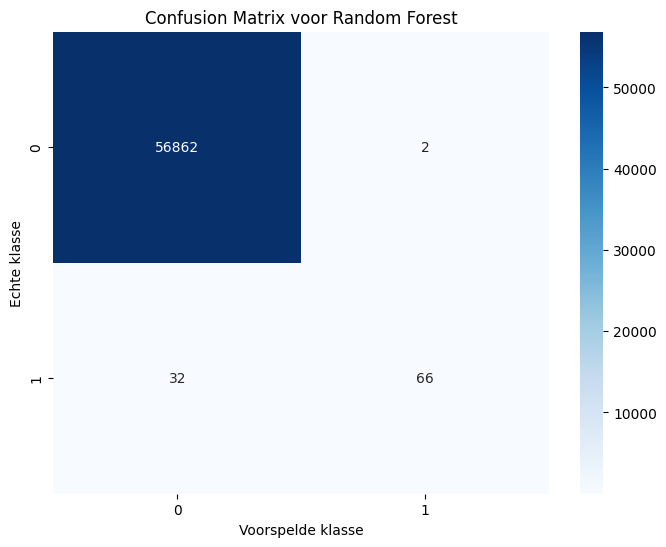

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("./creditcard.csv")
data.head()

# Input: alle kolommen behalve Class
X = data.drop(columns=["Class"])

# Output: de kolom die we willen voorspellen
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rnd_clf = RandomForestClassifier(n_estimators=500, max_leaf_nodes=16,
                                 n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
y_pred_rf = rnd_clf.predict(X_test)


accuracy_random_forest = accuracy_score(y_test, rnd_clf.predict(X_test))
print(accuracy_random_forest)

# --- Visualisatie ---
confusion_random_forest = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:")
print(confusion_random_forest)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_random_forest, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix voor Random Forest')
plt.xlabel('Voorspelde klasse')
plt.ylabel('Echte klasse')
plt.show()

feature_importances = rnd_clf.feature_importances_

features = pd.DataFrame({
'Feature': X.columns,
'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)



# Customer churn

Codering doelkolom: {'No': 0, 'Yes': 1}

Accuracy: 77.57%

Classification report:
              precision    recall  f1-score   support

          No      0.821     0.888     0.853      1035
         Yes      0.600     0.465     0.524       374

    accuracy                          0.776      1409
   macro avg      0.711     0.677     0.689      1409
weighted avg      0.763     0.776     0.766      1409



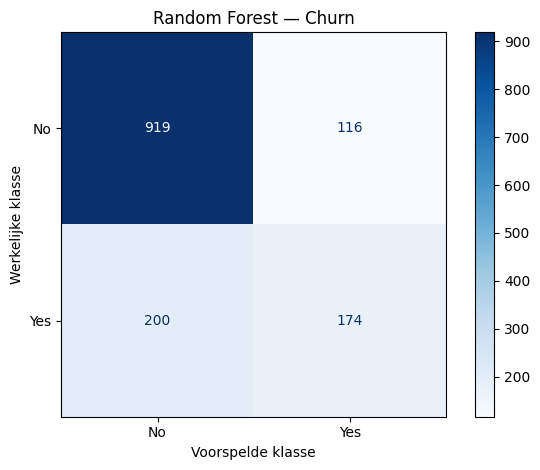

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# 1. Data inladen
data = pd.read_csv("./Telco-Customer-Churn.csv")

# Eerst omzetten, daarna pas X maken
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)


# 2. Input en doelkolom voorbereiden
X = data.drop(columns=["Churn", "customerID"]).copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data["Churn"])

print("Codering doelkolom:", dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))


# 3. Train- en testdata aanmaken
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 4. Numerieke kolommen voorbereiden
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# 5. Categorische kolommen voorbereiden
categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# 6. Beide voorbereidingen combineren
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# 7. Model kiezen
classifier = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


# 8. Voorbereiding en model samenvoegen
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])


# 9. Trainen
# De pipeline leert de voorbereiding uitsluitend uit X_train.
pipeline.fit(X_train, y_train)


# 10. Voorspellen
# De pipeline past automatisch dezelfde voorbereiding toe op X_test.
y_pred = pipeline.predict(X_test)


# 11. Evalueren
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2%}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=label_encoder.classes_,
    digits=3,
    zero_division=0
))


# 12. Confusion matrix tekenen
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest — Churn")
plt.xlabel("Voorspelde klasse")
plt.ylabel("Werkelijke klasse")
plt.tight_layout()
plt.show()